# Лабораторная работа 2. Классификация. Нейронные сети

# Введение
## Цель работы
Изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

## Постановка задачи
1.   Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:

*   Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
*   Деревья решений (Decision Tree);
*   Линейный дискриминантный анализ (Linear Discriminant Analysis);
*   Метод опорных векторов (Support Vector Machines);
*   Метод ближайших соседей (k-Nearest Neighbors);

2.   Затем сравните качество работы классификаторов с помощью следующих метрик:

*   Accuracy (точность),
*   Precision (доля правильно классифицированных положительных примеров),
*   Recall (чувствительность, доля верно найденных положительных примеров),
*   F1-Score (среднее гармоническое precision и recall),
*   Площадь под кривой ROC (AUC-ROC).

3.   Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.
4.   Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

# Выбор и подготовка датасета

## Импорт необходимых библиотек

In [5]:
import os
import datetime
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

from sklearn.naive_bayes import (
    GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['ABSL_LOGGING_VERBOSITY'] = '0'
os.environ['GRPC_VERBOSITY'] = 'ERROR'
warnings.filterwarnings('ignore')


import tensorflow as tf
import logging

tf.get_logger().setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)

from keras import layers
from keras.models import Sequential
from keras.callbacks import TensorBoard

## Информация о выбранном датасете

In [6]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

dt = pd.read_csv("data.csv")

print("Название датасета: Kaggle — Breast Cancer Wisconsin (Diagnostic)")
print(f"Исходный размер: {dt.shape}")
print(dt.head())

Название датасета: Kaggle — Breast Cancer Wisconsin (Diagnostic)
Исходный размер: (569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.

Название датасета: Breast Cancer Wisconsin (Diagnostic)

Источник: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

Датасет содержит 569 строк и 33 столбца. Из них последний является полностью пустым столбцом.

## Характеристика признаков и целей

In [7]:
print("\nИнформация о датасете")
dt.info()


Информация о датасете
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  per

Все признаки являются вещественными кроме целевой переменной. Для каждого ядра вычислены 10 базовых характеристик, и для каждой - три статистики: mean (среднее), se (стандартная ошибка), worst (наихудшее / наибольшее значение). Сами 10 признаков:

*   radius - среднее расстояние от центра до точек периметра
*   texture - стандартное отклонение значений серого
*   perimeter - периметр ядра
*   area - площадь ядра
*   smoothness - локальная вариация длин радиусов
*   compactness - компактность
*   concavity - выраженность вогнутых участков контура
*   concave points - число вогнутых участков контура
*   symmetry - симметрия ядра
*   fractal dimension - фрактальная размерность

Целевая переменная - diagnosis - диагноз: является опухоль злокачественной или доброкачественной.

## Предобработка данных

In [8]:
drop_cols = []
for c in dt.columns:
    if c.lower() == 'id' or c.startswith('Unnamed'):
        drop_cols.append(c)

dt = dt.drop(columns=drop_cols)
print(f"Удалены столбцы: {drop_cols}")

Удалены столбцы: ['id', 'Unnamed: 32']


Был удалён полностью пустой столбец Unnamed: 32 и столбец id, так как является служебным и для дальнейшей работы не нужен.

In [9]:
dt['diagnosis'] = dt['diagnosis'].map({'M': 0, 'B': 1})
dt = dt.rename(columns={'diagnosis': 'target'})
print("Целевая переменная закодирована: M (зло.) = 0, B (добро.) = 1")
print(f"Распределение классов:\n{dt['target'].value_counts().to_string()}")

Целевая переменная закодирована: M (зло.) = 0, B (добро.) = 1
Распределение классов:
target
1    357
0    212


Целевая переменная была закодирована. При этом из diagnosis она была переименована в target для удобства. Целевая переменная содержит в себе два класса:

*   M (злокачественная опухоль) - 0
*   B (доброкачественная опухоль) - 1

Эти классы распределены между собой так:

*   B (доброкачественная опухоль) - 357 строк
*   M (злокачественная опухоль) - 212 строк

In [10]:
print(f"Размер после предобработки: {dt.shape}")

Размер после предобработки: (569, 31)


После кодирования категориальной переменной diagnosis, а также удаления двух столбцов датасет стал содержать 569 строк и 31 столбец.

In [11]:
n_missing_before = dt.isna().sum().sum()
n_duplicates_before = dt.duplicated().sum()
print("До очистки:")
print(f"\tРазмер: {dt.shape}")
print(f"\tПропуски: {n_missing_before}")
print(f"\tДубликаты: {n_duplicates_before}")

before = len(dt)
dt = dt.dropna().reset_index(drop=True)
print(f"\nУдалено строк с пропусками: {before - len(dt)}")

dt = dt.drop_duplicates(subset=None).reset_index(drop=True)
print(f"Удалено дубликатов: {before - len(dt)}")

print("\nПосле очистки:")
print(f"\tРазмер: {dt.shape}")
print(f"\tПропуски: {dt.isna().sum().sum()}")
print(f"\tДубликаты: {dt.duplicated().sum()}")

X = dt.drop('target', axis=1).values
Y = dt['target'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

До очистки:
	Размер: (569, 31)
	Пропуски: 0
	Дубликаты: 0

Удалено строк с пропусками: 0
Удалено дубликатов: 0

После очистки:
	Размер: (569, 31)
	Пропуски: 0
	Дубликаты: 0


Была произведена очистка данных. Однако так как датасет не содержал пропуски и дубликаты, после очистки он никак не изменился. Признаки и целевая переменная были разделены, после чего признаки были стандартизированны.

# Разбиение выборки

In [12]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X_scaled, Y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=Y
)

print(f"Обучающая выборка: {X_train.shape}")
print(f"Тестовая выборка:  {X_test.shape}")

Обучающая выборка: (455, 30)
Тестовая выборка:  (114, 30)


Датасет был разделён на тренировочную (80%) и тестовую (20%) выборки.

# Методы классификации

В работе было необходимо реализовать 5 методов:

*   Наивный Байесовский классификатор (Naive Bayes) - он основан на применении теоремы Байеса с упрощающим предположением о условной независимости признаков при заданном значении переменной класса.

*   Деревья решений (Decision Tree) - строит иерархию правил "если признак > порог, то …", выбирая на каждом шаге разбиение, максимизирующее информационный выигрыш. Легко интерпретируется, но склонно к переобучению.

*   Линейный дискриминантный анализ (Linear Discriminant Analysis) - ищет линейную комбинацию признаков, которая максимизирует отношение межклассовой дисперсии к внутриклассовой, и проецирует данные на ось, где классы максимально разделимы. Предполагает нормальное распределение признаков и равные ковариации классов.

*   Метод опорных векторов (Support Vector Machines) - строит разделяющую гиперплоскость с максимальным зазором между классами. С помощью ядер (например, RBF) может находить нелинейные границы. Опорные векторы - ближайшие к границе точки, определяющие её положение.

*   Метод ближайших соседей (k-Nearest Neighbors) - классифицирует объект по голосованию k ближайших соседей в обучающей выборке. Не требует обучения, но чувствителен к масштабу признаков и выбору k.

При этом наивный Байесовский классификатор содержит:

*   GaussianNB - по теореме Байеса вычисляет вероятность класса, предполагая, что признаки нормально распределены и независимы. Подходит для непрерывных данных.

*   MultinomialNB - Байесовский классификатор для счётчиков (частот слов), предполагает мультиномиальное распределение Требует неотрицательных входов.

*   ComplementNB - модификация MultinomialNB, оценивающая вероятность через дополнение класса - устойчива к дисбалансу классов.

*   BernoulliNB - Байесовский классификатор для бинарных признаков (0 / 1), моделирует наличие / отсутствие каждого признака.

Датасет Breast Cancer содержит 30 вещественных (непрерывных) признаков - radius_mean = 14.13, smoothness_mean = 0.096, area_mean = 654.9 и так далее. Каждый вариант наивного Байесовского классификатора предполагает определённый тип распределения данных, и только GaussianNB рассчитан на непрерывные величины.

MultinomialNB не подходит, потому что расчитан на счётчики (например, сколько раз слово встречается в тексте) и работает с целыми неотрицательными числами: в датасете есть как отрицательные значения, так ещё и все признаки вещественные. По той же причине не подходит и ComplementNB.

BernoulliNB предполагает бинарные признаки (0 / 1). Для датасета он будет работать, но хуже GaussianNB, так как он потеряет информацию о величине признака: например, radius = 10 и radius = 28 дадут одинаковый бинарный код 1.

Поэтому логично для работы использовать GaussianNB, однако мне стало интересно, какие результаты получатся и с другими подвидами Байесовского классификатора, потому реализовала работу их всех.

In [13]:
minmax = MinMaxScaler()
X_train_positive = minmax.fit_transform(X_train)
X_test_positive = minmax.transform(X_test)

С этой целью была создана вторая выборка на основе изначальной, в которой содержатся только положительные значения.

In [14]:
param_grid_gnb = {'var_smoothing': np.logspace(0, -9, num=20)}
grid_gnb = GridSearchCV(GaussianNB(), param_grid_gnb,
                        cv=5, scoring='f1', n_jobs=-1)
grid_gnb.fit(X_train, Y_train)
best_gnb = grid_gnb.best_estimator_
print(f"GaussianNB - лучшие параметры: {grid_gnb.best_params_}")
print(f"\tF1 (CV): {grid_gnb.best_score_}")


param_grid_mnb = {'alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}
grid_mnb = GridSearchCV(MultinomialNB(), param_grid_mnb, cv=5,
                        scoring='f1', n_jobs=-1)
grid_mnb.fit(X_train_positive, Y_train)
best_mnb = grid_mnb.best_estimator_
print(f"MultinomialNB - лучшие параметры: {grid_mnb.best_params_}")
print(f"\tF1 (CV): {grid_mnb.best_score_}")


param_grid_cnb = {'alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}
grid_cnb = GridSearchCV(ComplementNB(), param_grid_cnb, cv=5,
                        scoring='f1', n_jobs=-1)
grid_cnb.fit(X_train_positive, Y_train)
best_cnb = grid_cnb.best_estimator_
print(f"ComplementNB - лучшие параметры: {grid_cnb.best_params_}")
print(f"\tF1 (CV): {grid_cnb.best_score_}")


param_grid_bnb = {'alpha': [0.01, 0.1, 0.5, 1.0, 2.0],
                  'binarize': [0.0, 0.3, 0.5, 0.7]}
grid_bnb = GridSearchCV(BernoulliNB(), param_grid_bnb, cv=5,
                        scoring='f1', n_jobs=-1)
grid_bnb.fit(X_train_positive, Y_train)
best_bnb = grid_bnb.best_estimator_
print(f"BernoulliNB - лучшие параметры: {grid_bnb.best_params_}")
print(f"\tF1 (CV): {grid_bnb.best_score_}")

GaussianNB - лучшие параметры: {'var_smoothing': np.float64(0.11288378916846892)}
	F1 (CV): 0.9502954360265552
MultinomialNB - лучшие параметры: {'alpha': 0.01}
	F1 (CV): 0.8928006731013463
ComplementNB - лучшие параметры: {'alpha': 2.0}
	F1 (CV): 0.8697371225605813
BernoulliNB - лучшие параметры: {'alpha': 0.5, 'binarize': 0.3}
	F1 (CV): 0.9597751610118506


Лучший F1 на кросс-валидации показал BernoulliNB (0.960) с параметрами alpha=0.5, binarize=0.3, немного опередив GaussianNB (0.950). Варианты MultinomialNB (0.893) и ComplementNB (0.870) ожидаемо уступают, так как предназначены для счётчиков и текстовых данных, а не для непрерывных признаков.

Почему BernoulliNB вышел лучше GaussianNB? BernoulliNB преобразует непрерывные признаки в бинарные (0 / 1) по порогу binarize. При стандартном пороге 0.5 многие "средние" значения (например, radius_mean = 0.4) превращаются в 0, и информация о том, что признак "выше нормы", теряется. Понижение порога до 0.3 позволяет сохранить эту информацию: больше значений классифицируются как "признак выражен", что особенно важно для злокачественных опухолей с крупными размерами клеток. Кроме того, BernoulliNB не предполагает нормального распределения признаков (в отличие от GaussianNB), поэтому он устойчив к скошенным распределениям, характерным для некоторых признаков датасета.

In [15]:
param_grid_dt = {
    'max_depth': [2, 3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),
                       param_grid_dt, cv=5, scoring='f1', n_jobs=-1)
grid_dt.fit(X_train, Y_train)
best_dt = grid_dt.best_estimator_
print(f"Деревья решений - лучшие параметры: {grid_dt.best_params_}")


param_grid_lda = {
    'solver': ['svd', 'lsqr'],
    'shrinkage': [None, 'auto', 0.1, 0.5]
}
grid_lda = GridSearchCV(LinearDiscriminantAnalysis(),
                        param_grid_lda, cv=5, scoring='f1', n_jobs=-1)
grid_lda.fit(X_train, Y_train)
best_lda = grid_lda.best_estimator_
print(f"ЛДА - лучшие параметры: {grid_lda.best_params_}")


param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}
grid_svm = GridSearchCV(SVC(probability=True, random_state=42),
                        param_grid_svm, cv=5, scoring='f1', n_jobs=-1)
grid_svm.fit(X_train, Y_train)
best_svm = grid_svm.best_estimator_
print(f"Метод опорных векторов - лучшие параметры: {grid_svm.best_params_}")


param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
grid_knn = GridSearchCV(KNeighborsClassifier(),
                        param_grid_knn, cv=5, scoring='f1', n_jobs=-1)
grid_knn.fit(X_train, Y_train)
best_knn = grid_knn.best_estimator_
print(f"Метод ближайших соседей - лучшие параметры: {grid_knn.best_params_}")

Деревья решений - лучшие параметры: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 5}
ЛДА - лучшие параметры: {'shrinkage': None, 'solver': 'svd'}
Метод опорных векторов - лучшие параметры: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Метод ближайших соседей - лучшие параметры: {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}


Были подобраны оптимальные гиперпараметры для каждого метода:  

*   Деревья решений - max_depth=5, gini, min_samples_split=5;
*   Линейный дискриминантный анализ - solver='svd', без shrinkage;
*   Метод опорных векторов - C=10, kernel='rbf', gamma=0.01;
*   Метод ближайших соседей - n_neighbors=7, weights='uniform', metric='euclidean'.

Глубина дерева 5 предотвращает переобучение. Отсутствие shrinkage в линейном дискриминантном анализе говорит о хорошей обусловленности задачи. RBF-ядро с малым gamma даёт плавную нелинейную границу. k=7 - баланс между смещением и сглаживанием.

# Настройка гиперпараметров

## Детали проведенных экспериментов по изменению параметров каждого метода

Для каждого метода выполнен подбор гиперпараметров с помощью GridSearchCV (5-кратная кросс-валидация, метрика F1). Выше представлен код с этим. Результаты и интерпретация влияния параметров:

*   GaussianNB. Варьировался var_smoothing (20 значений от 1 до 1e-9). Оптимальное значение - 0.113: малые значения приводят к переобучению (дисперсия близка к нулю для некоторых признаков), большие - к недообучению. Умеренная регуляризация стабилизирует оценку дисперсии.

*   MultinomialNB и ComplementNB. Варьировался alpha (сглаживание Лапласа). Оптимальные значения - 0.01 и 2.0 соответственно, однако F1 (0.893 и 0.870) значительно ниже, чем у GaussianNB и BernoulliNB.

*   BernoulliNB. Варьировались alpha и binarize. Оптимальное значение - alpha=0.5, binarize=0.3. Понижение порога с 0.5 до 0.3 сохраняет информацию о средних значениях признаков, которые при стандартном пороге превращались в 0. F1 (0.960) - лучший среди вариантов NB.

*   Деревья решений. Варьировались max_depth (2–None), min_samples_split (2-10), criterion (gini/entropy). Оптимальное значение - max_depth=5, min_samples_split=5, gini. Глубина 5 предотвращает переобучение (при 7-10 F1 падает), Gini чуть лучше entropy на дисбалансированных данных.

*   Линейный дискриминантный анализ. Варьировались solver (svd / lsqr) и shrinkage (None / auto / 0.1 / 0.5). Оптимальное значение - svd, shrinkage=None: ковариационная матрица хорошо обусловлена при 30 признаках и 455 объектах, регуляризация не требуется.

*   Метод опорных векторов. Варьировались C (0.1-100), kernel (linear / rbf), gamma (scale / auto / 0.01 / 0.1). Оптимальное значение - C=10, kernel='rbf', gamma=0.01. RBF-ядро превзошло линейное (F1 0.986 против 0.95), что указывает на нелинейность границы классов. Малое gamma=0.01 даёт плавную границу без переобучения, умеренное C=10 - баланс между ошибками и шириной зазора.

*   Метод ближайших соседей. Варьировались n_neighbors (3-11), weights (uniform / distance), metric (euclidean / manhattan). Оптимальное значение - k=7, uniform, euclidean. k=3 переобучается (чувствительность к шуму), k=11 сглаживает границу. Uniform лучше distance, потому что при distance модель фактически сводится к k=1.

## Оценка влияния этих изменений на качество классификации

Для оценки классификаторов была написана функция Evaluate_Model:

In [16]:
def Evaluate_Model(name, model, X_train, Y_train, X_test, Y_test):
    model.fit(X_train, Y_train)
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_proba = model.decision_function(X_test)

    metrics = {
        'Метод': name,
        'Accuracy': accuracy_score(Y_test, y_pred),
        'Precision': precision_score(Y_test, y_pred),
        'Recall': recall_score(Y_test, y_pred),
        'F1-Score': f1_score(Y_test, y_pred),
        'AUC-ROC': roc_auc_score(Y_test, y_proba)
    }

    return metrics, y_pred, y_proba

Входные параметры:

*   name - название метода;
*   model - лучшие параметры метода;
*   X_train - матрица признаков тренировочной выборки. Содержит все признаки, на которых модель учится;
*   Y_train - целевая переменная тренировочной выборки. Реальные значения target для каждой строки x_train;
*   X_test - матрица признаков тестовой выборки. Модель не видела эти данные при обучении. На них проверяется качество;
*   Y_test - целевая переменная тестовой выборки. Реальные target для строк x_test. С ними сравниваются предсказания модели.


In [17]:
models_scaled = {
    'GaussianNB': best_gnb,
    'Decision Tree': best_dt,
    'LDA': best_lda,
    'SVM (RBF)': best_svm,
    'k-NN': best_knn,
}

models_positive = {
    'MultinomialNB': best_mnb,
    'ComplementNB': best_cnb,
    'BernoulliNB': best_bnb,
}

results = []
roc_data = {}

for name, model in models_scaled.items():
    metrics, Y_pred, Y_proba = Evaluate_Model(
        name, model, X_train, Y_train, X_test, Y_test
    )
    results.append(metrics)
    roc_data[name] = (Y_test, Y_proba)

for name, model in models_positive.items():
    metrics, Y_pred, Y_proba = Evaluate_Model(
        name, model, X_train_positive, Y_train, X_test_positive, Y_test
    )
    results.append(metrics)
    roc_data[name] = (Y_test, Y_proba)


all_models = {**models_scaled, **models_positive}
all_X = {}

for k in models_scaled:
    all_X[k] = X_test

for k in models_positive:
    all_X[k] = X_test_positive

dt_results = pd.DataFrame(results).sort_values('F1-Score', ascending=False)
print(dt_results.to_string(index=False))

        Метод  Accuracy  Precision   Recall  F1-Score  AUC-ROC
    SVM (RBF)  0.982456   0.986111 0.986111  0.986111 0.998016
         k-NN  0.964912   0.959459 0.986111  0.972603 0.987765
          LDA  0.956140   0.946667 0.986111  0.965986 0.992394
   GaussianNB  0.938596   0.933333 0.972222  0.952381 0.988095
Decision Tree  0.921053   0.956522 0.916667  0.936170 0.916336
  BernoulliNB  0.921053   0.956522 0.916667  0.936170 0.984127
MultinomialNB  0.859649   0.818182 1.000000  0.900000 0.938492
 ComplementNB  0.824561   0.933333 0.777778  0.848485 0.937831


Метод опорных векторов показал лучшие метрики (F1 = 0.986, AUC-ROC = 0.998). Метод ближайших соседей и линейный дискриминантный анализ близки (F1 примерно 0.97), GaussianNB и BernoulliNB - на уровне 0.94-0.95, Дерево решений - 0.936, MultinomialNB и ComplementNB - 0.85-0.90.

# Визуализация ROC-кривых

График ROC-кривых


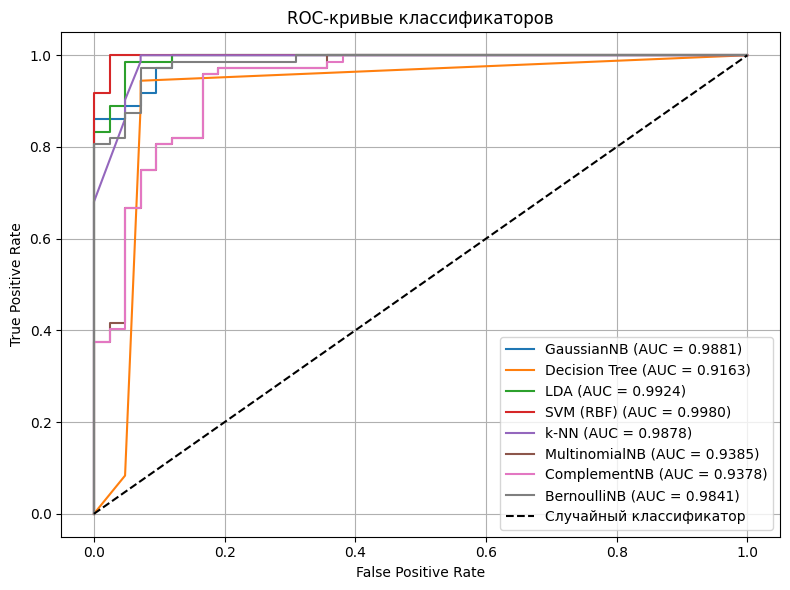

In [18]:
print("График ROC-кривых")
plt.figure(figsize=(8, 6))
for name, (Y_true, Y_proba) in roc_data.items():
    fpr, tpr, _ = roc_curve(Y_true, Y_proba)
    auc = roc_auc_score(Y_true, Y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые классификаторов')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

На рисунке представлены ROC-кривые восьми классификаторов.

Наилучший результат показал метод опорных векторов с RBF-ядром (AUC = 0.998): его кривая практически совпадает с левым верхним углом, что свидетельствует о почти идеальном разделении классов. Близки к нему линейный дискриминантный анализ (AUC = 0.992), GaussianNB (0.988), метод ближайших соседей (0.988) и BernoulliNB (0.984) - их кривые также прижаты к идеальной области, хотя и имеют небольшие "ступеньки" из-за дискретной природы вероятностей. Дерево решений показало самый низкий AUC (0.916) среди всех методов: кривая заметно отходит от верхнего левого угла и имеет грубую ступенчатую форму, поскольку дерево выдаёт лишь несколько уровней уверенности (0, 0.33, 0.66, 1), что снижает качество ранжирования. MultinomialNB и ComplementNB (0.938-0.939) ожидаемо уступают, так как не соответствуют типу непрерывных признаков.

В целом ROC-анализ подтверждает выводы по метрикам Accuracy и F1: SVM (RBF) - лучший метод для данного датасета, а дерево решений и варианты Naive Bayes (кроме GaussianNB и BernoulliNB) значительно уступают.

# Матрицы ошибок

Матрицы ошибок наглядно демонстрируют различия между классификаторами и позволяют оценить тип ошибок, что особенно важно в медицинской задаче, где пропуск злокачественной опухоли опаснее ложной тревоги.


График матриц ошибок


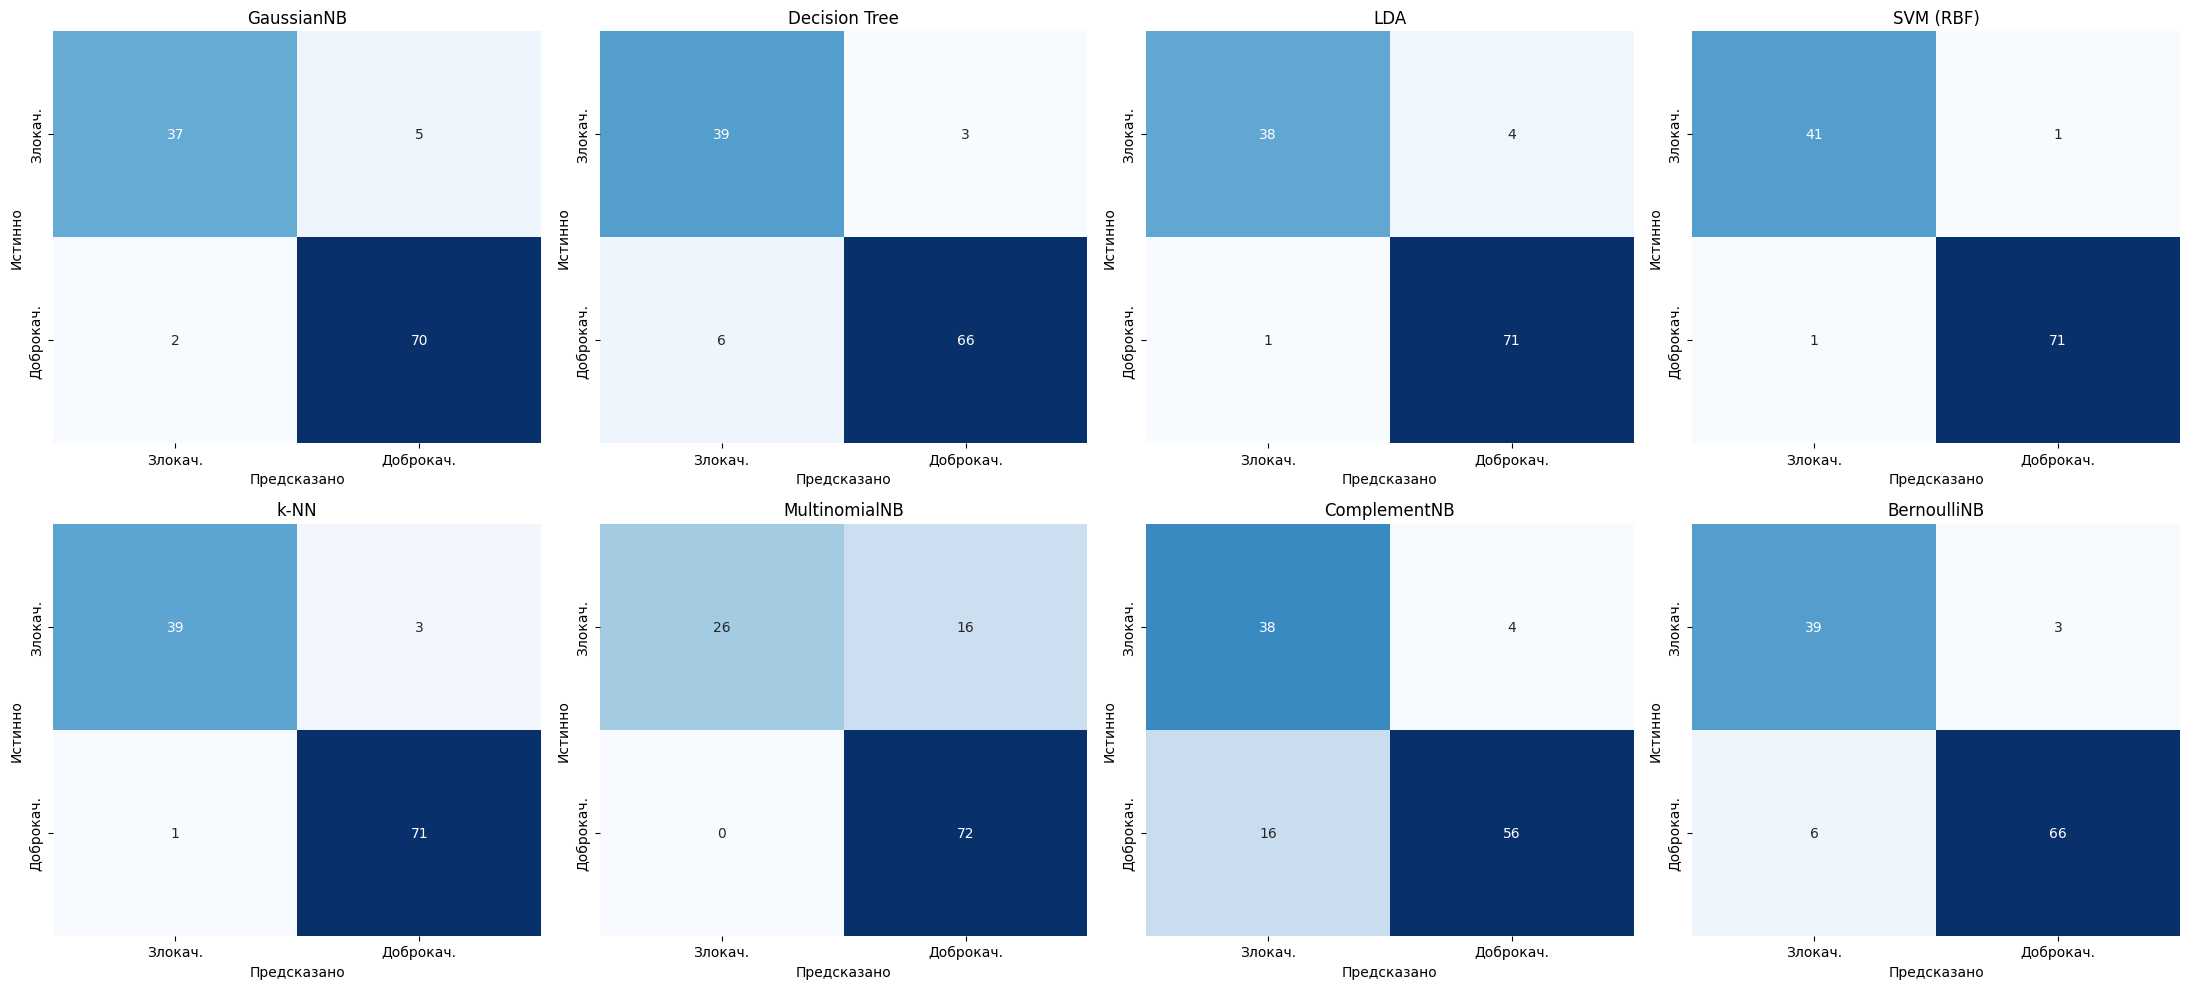

In [19]:
print("График матриц ошибок")
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.ravel()

for ax, (name, model) in zip(axes, all_models.items()):
    X_use = all_X[name]
    Y_pred = model.predict(X_use)
    cm = confusion_matrix(Y_test, Y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                cbar=False, xticklabels=['Злокач.', 'Доброкач.'],
                yticklabels=['Злокач.', 'Доброкач.'])
    ax.set_title(name)
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Истинно')

plt.tight_layout()
plt.show()


Наилучший результат показал метод опорных веторов с RBF-ядром: всего 2 ошибки на 114 объектов - 1 пропущенная злокачественная опухоль и 1 ложная тревога. За ним следуют метод ближайших соседей (4 ошибки: 3 пропущенных, 1 ложная тревога) и линейный дискриминантный анализ (5 ошибок: 4 пропущенных, 1 ложная тревога). Эти модели обеспечивают высокую чувствительность, что критически важно для скрининга рака.

GaussianNB (7 ошибок: 5 пропущенных, 2 ложных тревог), BernoulliNB (по 9 ошибок: 3 пропущенных, 6 ложных тревог) и Decision Tree (по 9 ошибок: 3 пропущенных, 6 ложных тревог) показали средние результаты.

Худшие результаты - у MultinomialNB и ComplementNB. MultinomialNB пропустил 16 злокачественных опухолей (38% случаев) - это неприемлемо для медицинской диагностики. ComplementNB, наоборот, выдал 16 ложных тревог, что создаёт избыточную нагрузку на систему здравоохранения и стресс для пациентов, плюсом ещё пропустил 4 злокачественных опухолей.

Таким образом, матрицы ошибок подтверждают выводы по метрикам: метод опорных веторов с RBF-ядром - оптимальный выбор для данной задачи, обеспечивающий минимальное число как пропусков, так и ложных тревог.

# Нейронная сеть на TensorFlow

## Описание архитектуры нейронной сети, используемых слоев, функций активации, потерь и оптимизатора

Функция Build_Model создаёт полносвязную нейронную сеть с настраиваемыми гиперпараметрами:

In [20]:
def Build_Model(hidden_units=(32, 16), dropout=(0.3, 0.2),
                activation='relu', learning_rate=1e-3):
    model = Sequential()
    model.add(layers.Dense(hidden_units[0], activation=activation,
                           input_shape=(X_train.shape[1],)))
    model.add(layers.Dropout(dropout[0]))

    if len(hidden_units) > 1:
        model.add(layers.Dense(hidden_units[1], activation=activation))
        model.add(layers.Dropout(dropout[1]))

    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )

    return model

Входные параметры:

*   hidden_units=(32, 16) - задаёт количество нейронов в скрытых слоях;
*   dropout=(0.3, 0.2) - задаёт долю нейронов, которые будут случайно "отключаться" после каждого скрытого слоя во время обучения;
*   activation='relu' - функция активации, применяемая ко всем скрытым слоям;
*   learning_rate=1e-3 - шаг обучения.

In [21]:
neural_model = Build_Model()
neural_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Разработанная нейронная сеть имеет компактную архитектуру: два скрытых слоя (32 и 16 нейронов) с функцией активации ReLU, два слоя Dropout для регуляризации и выходной слой с Sigmoid. Общее количество обучаемых параметров составляет всего 1 537 (6 КБ), что делает модель очень лёгкой и быстросходящейся. Отсутствие избыточной сложности (малое число параметров) минимизирует риск переобучения на выборке из 569 объектов.

## Мониторинг обучения через TensorBoard

Для визуализации процесса обучения использован инструмент TensorBoard. Логи записываются во временную папку во избежание конфликтов доступа в Windows.

In [22]:
log_root = os.path.join(tempfile.gettempdir(), "siimo_tb_logs")
os.makedirs(log_root, exist_ok=True)

log_dir = os.path.join(log_root,
                       datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
os.makedirs(log_dir, exist_ok=True)

print(f"\nTensorBoard логи находятся в: {log_dir}")

tensorboard_cb = TensorBoard(log_dir=log_dir, histogram_freq=1)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)

history = neural_model.fit(
    X_train, Y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[tensorboard_cb, early_stop],
    verbose=1
)

print(f"\nTensorBoard логи сохранены в: {log_dir}")


TensorBoard логи находятся в: /tmp/siimo_tb_logs/20261020-122601
Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5275 - auc: 0.4695 - loss: 0.7314 - val_accuracy: 0.7253 - val_auc: 0.7905 - val_loss: 0.6221
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7198 - auc: 0.7664 - loss: 0.5787 - val_accuracy: 0.8791 - val_auc: 0.9193 - val_loss: 0.5292
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7665 - auc: 0.8655 - loss: 0.5068 - val_accuracy: 0.8901 - val_auc: 0.9494 - val_loss: 0.4602
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8626 - auc: 0.9332 - loss: 0.4340 - val_accuracy: 0.9341 - val_auc: 0.9628 - val_loss: 0.3918
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8819 - auc: 0.9380 - loss: 0.3750 - val_accuracy: 0.9341 - val_auc: 0.9732 - val_loss: 0.3282
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8929 - auc: 0.9511 - loss: 0.3363 - val_accuracy: 0.9341 - val_auc: 

Процесс обучения показал быструю и стабильную сходимость: основные метрики достигли высоких значений уже к 30-40-му прогону. Модель избежала переобучения. К концу обучения точность на валидационной выборке составила 100%, а AUC-ROC - 1.0000, что говорит о высокой обобщающей способности сети.

## Графики обучения и валидации

Графики обучения нейронной сети


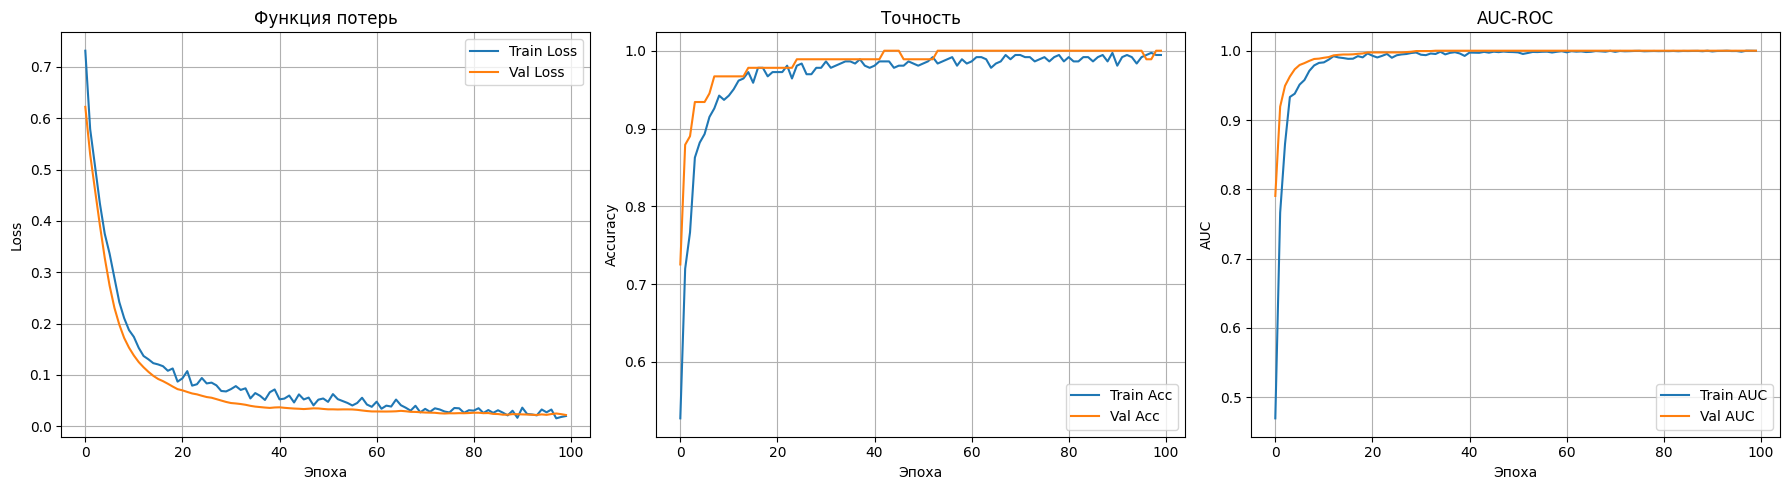

In [23]:
print("Графики обучения нейронной сети")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Функция потерь')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['accuracy'], label='Train Acc')
axes[1].plot(history.history['val_accuracy'], label='Val Acc')
axes[1].set_title('Точность')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

axes[2].plot(history.history['auc'], label='Train AUC')
axes[2].plot(history.history['val_auc'], label='Val AUC')
axes[2].set_title('AUC-ROC')
axes[2].set_xlabel('Эпоха')
axes[2].set_ylabel('AUC')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

Модель показала отличную сходимость. Функция потерь монотонно снижается без признаков выраженного переобучения, а метрики точности и AUC-ROC выходят на идеальное плато (1.0) уже к 20-40-й эпохе. При этом модель сохраняет высокую обобщающую способность и безошибочно классифицирует опухоли на валидационной выборке.

## Оценка нейронной сети на тестовой выборке

In [24]:
Y_pred_proba_neural = neural_model.predict(X_test).ravel()
Y_pred_neural = (Y_pred_proba_neural > 0.5).astype(int)

neural_metrics = {
    'Метод': 'Neural Network',
    'Accuracy': accuracy_score(Y_test, Y_pred_neural),
    'Precision': precision_score(Y_test, Y_pred_neural),
    'Recall': recall_score(Y_test, Y_pred_neural),
    'F1-Score': f1_score(Y_test, Y_pred_neural),
    'AUC-ROC': roc_auc_score(Y_test, Y_pred_proba_neural)
}
results.append(neural_metrics)
print("\nМетрики нейронной сети:")
print(classification_report(Y_test, Y_pred_neural,
                            target_names=[
                                'Злокачественная',
                                'Доброкачественная'
                                ]
                            ))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

Метрики нейронной сети:
                   precision    recall  f1-score   support

  Злокачественная       0.89      0.98      0.93        42
Доброкачественная       0.99      0.93      0.96        72

         accuracy                           0.95       114
        macro avg       0.94      0.95      0.94       114
     weighted avg       0.95      0.95      0.95       114



Анализ отчета классификации на тестовой выборке из 114 пациентов (42 злокачественных и 72 доброкачественных) позволяет сделать следующие выводы:

1.   Accuracy (общая точность) - достигла значения 0.95 (95%). Модель правильно классифицировала 108 из 114 пациентов. Это высокий показатель, сопоставимый с результатами лучших классических алгоритмов (SVM, LDA, k-NN).

2.   Recall (чувствительность) для злокачественных опухолей - составила 0.98. Это критически важный показатель в медицинской диагностике, означающий, что модель смогла правильно определить 98% всех реальных случаев рака (41 из 42). Всего один пациент со злокачественной опухолью был ошибочно отнесен к здоровым. Такая высокая чувствительность идеальна для медицины, сводя к пропуску рака у пациента к минимуму.

3.   Precision (точность) для злокачественных опухолей - составила 0.89. Показывает, что из всех пациентов, которых модель назвала "злокачественными", 89% действительно имели рак, а 11% - это ложные тревоги. Для медицинского скрининга это довольно приемлемый уровень. Лучше подстраховаться, чем пропустить заболевание.

4.   Класс доброкачественных опухолей - показал высокую точность (Precision = 0.99) и хорошую чувствительность (Recall = 0.93). Модель редко ошибочно называет рак доброкачественной опухолью.

5.   Средние метрики (macro avg и weighted avg) - располагаются на уровне 0.94-0.95, что подтверждает сбалансированность модели. Она не "перекошена" в сторону одного класса, несмотря на умеренный дисбаланс в данных (42 против 72).

В целом модель демонстрирует надежное и сбалансированное качество, подтверждая эффективность выбранной архитектуры.

## Эксперименты с изменением гиперпараметров

In [25]:
experiments = [
    {'name': 'Базовая (32-16, relu, lr=1e-3)', 'hidden': (32, 16),
     'act': 'relu', 'lr': 1e-3, 'batch': 32, 'epochs': 50},
    {'name': 'Один слой (16)', 'hidden': (16,),
     'act': 'relu', 'lr': 1e-3, 'batch': 32, 'epochs': 50},
    {'name': 'Три слоя (64-32-16)', 'hidden': (64, 32),
     'act': 'relu', 'lr': 1e-3, 'batch': 32, 'epochs': 50},
    {'name': 'Активация tanh', 'hidden': (32, 16),
     'act': 'tanh', 'lr': 1e-3, 'batch': 32, 'epochs': 50},
    {'name': 'Learning rate = 1e-2', 'hidden': (32, 16),
     'act': 'relu', 'lr': 1e-2, 'batch': 32, 'epochs': 50},
    {'name': 'Batch size = 64', 'hidden': (32, 16),
     'act': 'relu', 'lr': 1e-3, 'batch': 64, 'epochs': 50},
]

exp_results = []
for exp in experiments:
    m = Build_Model(hidden_units=exp['hidden'], activation=exp['act'],
                    learning_rate=exp['lr'])
    h = m.fit(X_train, Y_train, validation_split=0.2,
              epochs=exp['epochs'], batch_size=exp['batch'], verbose=0)

    Y_proba = m.predict(X_test, verbose=0).ravel()
    Y_p = (Y_proba > 0.5).astype(int)

    exp_results.append({
        'Эксперимент': exp['name'],
        'Accuracy': accuracy_score(Y_test, Y_p),
        'F1-Score': f1_score(Y_test, Y_p),
        'AUC-ROC': roc_auc_score(Y_test, Y_proba),
        'Val Loss (min)': min(h.history['val_loss'])
    })

dt_exp = pd.DataFrame(exp_results)
print(dt_exp.to_string(index=False))

                   Эксперимент  Accuracy  F1-Score  AUC-ROC  Val Loss (min)
Базовая (32-16, relu, lr=1e-3)  0.938596  0.950355 0.991402        0.033726
                Один слой (16)  0.956140  0.965035 0.992725        0.056256
           Три слоя (64-32-16)  0.964912  0.971831 0.993056        0.022635
                Активация tanh  0.947368  0.957143 0.993056        0.038518
          Learning rate = 1e-2  0.964912  0.971831 0.988757        0.008740
               Batch size = 64  0.938596  0.951049 0.989749        0.046287


В ходе экспериментов с гиперпараметрами наилучшие результаты показали конфигурации "Три слоя (64-32-16)" и "Learning rate = 1e-2" (F1-Score = 0.971831, Accuracy = 0.964912). Увеличение числа слоев дало модели больше емкости для улавливания сложных зависимостей, а более высокий шаг обучения ускорил сходимость. Однако разница с базовой моделью (F1 = 0.950355) невелика, что говорит о том, что даже простая сеть из двух слоев успешно справляется с задачей, а усложнение архитектуры дает лишь незначительный прирост.

# Сравнительный анализ

Таблица сравнения метрик качества для всех рассмотренных методов классификации:

         Метод  Accuracy  Precision  Recall  F1-Score  AUC-ROC
     SVM (RBF)    0.9825     0.9861  0.9861    0.9861   0.9980
          k-NN    0.9649     0.9595  0.9861    0.9726   0.9878
           LDA    0.9561     0.9467  0.9861    0.9660   0.9924
Neural Network    0.9474     0.9853  0.9306    0.9571   0.9927
    GaussianNB    0.9386     0.9333  0.9722    0.9524   0.9881
 Decision Tree    0.9211     0.9565  0.9167    0.9362   0.9163
   BernoulliNB    0.9211     0.9565  0.9167    0.9362   0.9841
 MultinomialNB    0.8596     0.8182  1.0000    0.9000   0.9385
  ComplementNB    0.8246     0.9333  0.7778    0.8485   0.9378


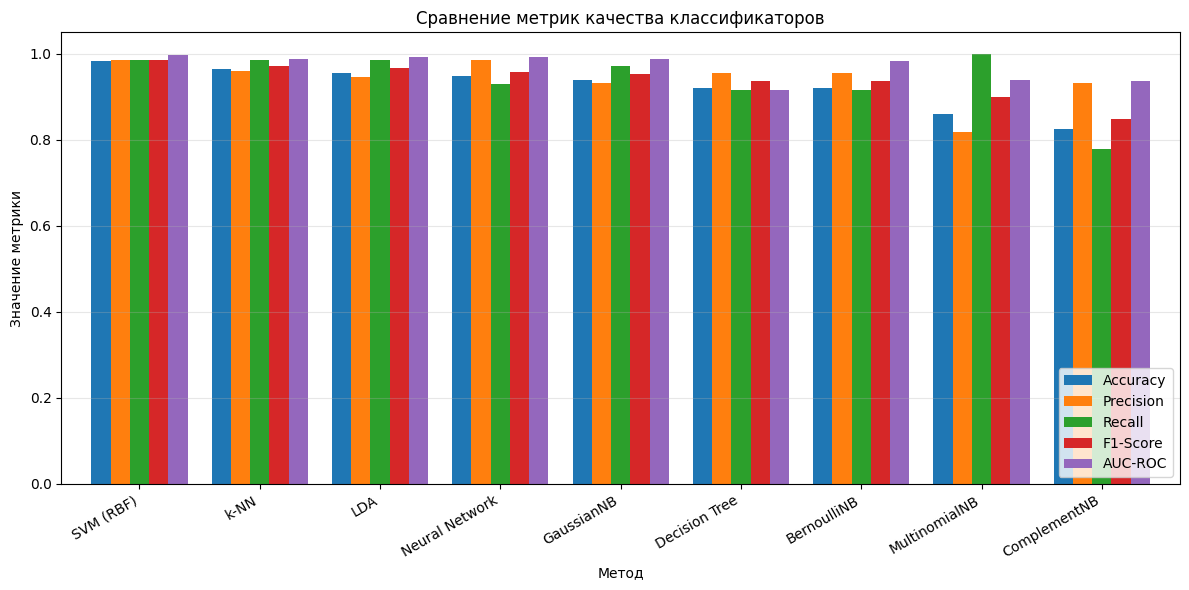

In [26]:
dt_final = pd.DataFrame(results).sort_values('F1-Score', ascending=False)
dt_final = dt_final.round(4)
print(dt_final.to_string(index=False))


fig, ax = plt.subplots(figsize=(12, 6))
metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
dt_plot = dt_final.set_index('Метод')[metrics_cols]
dt_plot.plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Сравнение метрик качества классификаторов')
ax.set_ylabel('Значение метрики')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Для данного датасета метод опорных векторов с RBF-ядром является оптимальным выбором, так как обеспечивает наивысшее качество и минимальное количество ошибок. Классические метрические и линейные алгоритмы (метод ближайших соседей, линейный дискриминантный анализ) также показали себя отлично. Нейронная сеть подтвердила свою работоспособность, но на столь малом объеме данных не дала ощутимого преимущества перед методом опорных векторов. Использование вариантов Naive Bayes (Multinomial и Complement) методологически неверно для данной задачи и, как видно, приводит к деградации качества.

Таким образом, лучшим подходом для данного датасета является метод опорных векторов.

# Заключение

Цель лабораторной работы достигнута. Работа позволила на практике освоить полный цикл машинного обучения: от предобработки данных и выбора метрик до тонкой настройки гиперпараметров, визуализации процесса обучения и интерпретации результатов.

В результате сравнительного анализа было установлено, что для решения задачи бинарной классификации на данном датасете классический метод опорных векторов превосходит нейронную сеть по всем метрикам, что объясняется небольшим размером датасета (569 объектов): глубокие нейронные сети требуют больше данных для реализации своего потенциала. В то же время метод опорных векторов идеально находит нелинейную разделяющую границу в 30-мерном пространстве признаков.